Implementation of KNN Regressor and KNN Classifier

pandas is a software library written for the Python programming language for data manipulation and analysis. In particular, it offers data structures and operations for manipulating numerical tables and time series as well as reading data from csv file.

In [ ]:
# importing necessary source
import pandas as pd
# Here, "import" is a key word of python to install some external package
# that is not present with python by default and "as" is a key word to rename any external package with our name in that project
import numpy as np
import matplotlib.pyplot as plt # matplotlib for ploting data
from sklearn.model_selection import train_test_split # for train and test data
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor # KNN regressor
from sklearn.metrics import accuracy_score

In [ ]:
# for uploading data from local machine we can use this code
from google.colab import files # here files is a module from google.colab where we can get many functions to use
uploaded = files.upload() # upload() is a function to access the file from local computer

In [ ]:
# for saving dataset that is uploaded from local machine
import io # io module allows us to manage the file-related input and output operations
df = pd.read_csv(io.BytesIO(uploaded['tree.csv']))
# in [] give the name of the file that you have uploaded, here df is a variable to store data, pd is panda library which we imported first, read_csv is a function of panda that will read csv
# file, io.BytesIO is a method to convert a byte data into file/object data
print(df) # this will will simple print the data

In [ ]:
from google.colab import drive # permission for inserting dataset from google drive
drive.mount('/content/drive') # make drive accessible

Mounted at /content/drive


# Data Collection and Preprocessing

In [ ]:
wh_data = pd.read_csv('/content/drive/Shareddrives/Research_datasets/weight-height.csv') # inserting data from google drive, wh_data is a variable to store data
wh_data.head() # show first 5 data

,Gender,Height,Weight
0,Male,73.847017,241.893563
1,Male,68.781904,162.310473
2,Male,74.110105,212.740856
3,Male,71.730978,220.042470
4,Male,69.881796,206.349801


In [ ]:
wh_data.shape # view the shape of data

(8555, 3)

In [ ]:
wh_data.isnull().sum() # view is there any null value

Gender    0
Height    0
Weight    0
dtype: int64

In [ ]:
from sklearn.preprocessing import LabelEncoder # for enconding Gender

In [ ]:
enc = LabelEncoder()
# The fit(data) method is used to compute the mean and std dev for a given feature to be
# used further for scaling. The transform(data) method is used to perform scaling using
# mean and std dev calculated using the . fit() method. The fit_transform() method does both fits and transform.
wh_data['Gender'] = enc.fit_transform(wh_data['Gender']) # endocing Gender from string to number

In [ ]:
wh_data.head() # view first 5 data from dataset

,Gender,Height,Weight
0,1,73.847017,241.893563
1,1,68.781904,162.310473
2,1,74.110105,212.740856
3,1,71.730978,220.042470
4,1,69.881796,206.349801


In [ ]:
wh_data.tail() # view first 5 data from dataset

,Gender,Height,Weight
8550,0,60.483946,110.565497
8551,0,63.423372,129.921671
8552,0,65.584057,155.942671
8553,0,67.429971,151.678405
8554,0,60.921791,131.253738


In [ ]:
# dividing data into target and attribute
x = wh_data.drop('Weight', axis=1) # attibute data
y = wh_data['Weight'] # target data

In [ ]:
print(x.shape)
print(y.shape)

(8555, 2)
(8555,)


# Train and Test data

In [ ]:
xtrain, xtest, ytrain, ytest = train_test_split(x, y, test_size=0.3, random_state=1) # train and test data by train_test_split

In [ ]:
print(x.shape, xtrain.shape, xtest.shape)

(8555, 2) (5988, 2) (2567, 2)


# Model Training --> LinearRegression

In [ ]:
linearModel = LinearRegression() #taking object of linearRegression

In [ ]:
linearModel.fit(xtrain, ytrain) # here fit is a function that will train the model with our feature training data and correspondent label traing data of the feature training data

LinearRegression()

# Model Evaluation --> LinearRegression

In [ ]:
linearAccuracy = linearModel.score(xtest, ytest) # accuracy score of dataset for linearRegression

In [ ]:
 # Python predict() function enables us to predict the labels of the data values
# on the basis of the trained model. The predict() function accepts only a single argument which is usually the data to be tested.
 pred_y = linearModel.predict(xtest) # prediction of test data for liearRegression model

In [ ]:
#Finding Mean Square Error
from sklearn.metrics import mean_squared_error
mse_linear = mean_squared_error(ytest, pred_y)

In [ ]:
wh_data['Linear_pred_Weight'] = linearModel.predict(x) # making new column of predicted result named as Linear_pred_weight

In [ ]:
print('Accuracy of LinearReagression ', linearAccuracy) # showing accury find by linearRegression
print('Mean Square Error of LinearRegression ', mse_linear) # showing mean square error find by linearRegression
print(wh_data.head()) # show first five data from entire dataset
print(wh_data.tail()) # show last five data from entire dataset

Accuracy of LinearReagression  0.905995960709116
Mean Square Error of LinearRegression  99.67250998070033
   Gender     Height      Weight  Linear_pred_Weight
0       1  73.847017  241.893563          215.574352
1       1  68.781904  162.310473          185.341329
2       1  74.110105  212.740856          217.144694
3       1  71.730978  220.042470          202.943984
4       1  69.881796  206.349801          191.906445
      Gender     Height      Weight  Linear_pred_Weight
8550       0  60.483946  110.565497          116.468265
8551       0  63.423372  129.921671          134.013329
8552       0  65.584057  155.942671          146.910187
8553       0  67.429971  151.678405          157.928220
8554       0  60.921791  131.253738          119.081708


# Model Training --> KNeighborsRegressor

In [ ]:
from sklearn.neighbors import KNeighborsRegressor # importing KNeighborsRegressor from scikit learn

In [ ]:
knn = KNeighborsRegressor() # creating object of KNeighborsRegressor

In [ ]:
knn.fit(xtrain, ytrain) # here fit is a function that will train the model with our feature training data and correspondent label traing data of the feature training data

KNeighborsRegressor()

# Model Evaluation --> KNeighborsRegressor

In [ ]:
knnAccuracy = knn.score(xtest, ytest) # finding accuracy by KNeighborsRegressor

In [ ]:
y_pred_knn = knn.predict(xtest) # predicting result after training dataset with KNeighborsRegressor

In [ ]:
#Finding Mean Square Error for KNeighborsRegressor
from sklearn.metrics import mean_squared_error
mse_knn = mean_squared_error(ytest, y_pred_knn)

In [ ]:
wh_data['knn_pred_Weight'] = knn.predict(x) # creating new column for predicted results by KNeighborsRegressor

In [ ]:
print('Accuracy of KNeighborsRegressor ', knnAccuracy) # showing accury find by KNeighborsRegressor
print('Mean Square Error of KNeighborsRegressor ', mse_knn) # showing mean square error find by KNeighborsRegressor
print(wh_data.head()) # show first five data from entire dataset
print(wh_data.tail()) # show last five data from entire dataset

Accuracy of KNeighborsRegressor  0.8838502073708883
Mean Square Error of KNeighborsRegressor  123.15365863436983
   Gender     Height      Weight  Linear_pred_Weight  knn_pred_Weight
0       1  73.847017  241.893563          215.574352       222.249723
1       1  68.781904  162.310473          185.341329       181.243871
2       1  74.110105  212.740856          217.144694       220.883791
3       1  71.730978  220.042470          202.943984       199.347460
4       1  69.881796  206.349801          191.906445       193.719655
      Gender     Height      Weight  Linear_pred_Weight  knn_pred_Weight
8550       0  60.483946  110.565497          116.468265       114.899508
8551       0  63.423372  129.921671          134.013329       135.770862
8552       0  65.584057  155.942671          146.910187       146.748282
8553       0  67.429971  151.678405          157.928220       161.587442
8554       0  60.921791  131.253738          119.081708       118.242226


# Optimizing Algorithm with Hyper parameter Tuning

In [ ]:
# Randomized Search CV for tuning dataset
from sklearn.model_selection import RandomizedSearchCV

In [ ]:
#List Hyperparameters that we want to tune.
leaf_size = list(range(1,50))
n_neighbors = list(range(1,1000))
p=[1,2]

grids = {
    'leaf_size': leaf_size,
    'n_neighbors': n_neighbors,
    'p': p
}

In [ ]:
grids

{'leaf_size': [1,
  2,
  3,
  4,
  5,
  6,
  7,
  8,
  9,
  10,
  11,
  12,
  13,
  14,
  15,
  16,
  17,
  18,
  19,
  20,
  21,
  22,
  23,
  24,
  25,
  26,
  27,
  28,
  29,
  30,
  31,
  32,
  33,
  34,
  35,
  36,
  37,
  38,
  39,
  40,
  41,
  42,
  43,
  44,
  45,
  46,
  47,
  48,
  49],
 'n_neighbors': [1,
  2,
  3,
  4,
  5,
  6,
  7,
  8,
  9,
  10,
  11,
  12,
  13,
  14,
  15,
  16,
  17,
  18,
  19,
  20,
  21,
  22,
  23,
  24,
  25,
  26,
  27,
  28,
  29,
  30,
  31,
  32,
  33,
  34,
  35,
  36,
  37,
  38,
  39,
  40,
  41,
  42,
  43,
  44,
  45,
  46,
  47,
  48,
  49,
  50,
  51,
  52,
  53,
  54,
  55,
  56,
  57,
  58,
  59,
  60,
  61,
  62,
  63,
  64,
  65,
  66,
  67,
  68,
  69,
  70,
  71,
  72,
  73,
  74,
  75,
  76,
  77,
  78,
  79,
  80,
  81,
  82,
  83,
  84,
  85,
  86,
  87,
  88,
  89,
  90,
  91,
  92,
  93,
  94,
  95,
  96,
  97,
  98,
  99,
  100,
  101,
  102,
  103,
  104,
  105,
  106,
  107,
  108,
  109,
  110,
  111,
  112,
  113,
  1

In [ ]:
# Randomized Search CV
rscv = RandomizedSearchCV(knn,grids, n_iter=500, cv=3) # giving listed parameters for tuning the dataset

In [ ]:
rscv.fit(xtrain,ytrain) # traing the dataset by randomized search cv

RandomizedSearchCV(cv=3, estimator=KNeighborsRegressor(), n_iter=500,
                   param_distributions={'leaf_size': [1, 2, 3, 4, 5, 6, 7, 8, 9,
                                                      10, 11, 12, 13, 14, 15,
                                                      16, 17, 18, 19, 20, 21,
                                                      22, 23, 24, 25, 26, 27,
                                                      28, 29, 30, ...],
                                        'n_neighbors': [1, 2, 3, 4, 5, 6, 7, 8,
                                                        9, 10, 11, 12, 13, 14,
                                                        15, 16, 17, 18, 19, 20,
                                                        21, 22, 23, 24, 25, 26,
                                                        27, 28, 29, 30, ...],
                                        'p': [1, 2]})

In [ ]:
results = pd.DataFrame(rscv.cv_results_) # results after tuning dataset

In [ ]:
results # showing all the results after tuning

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_p,param_n_neighbors,param_leaf_size,params,split0_test_score,split1_test_score,split2_test_score,mean_test_score,std_test_score,rank_test_score
0,0.003908,0.000158,0.182932,0.008139,2,597,18,"{'p': 2, 'n_neighbors': 597, 'leaf_size': 18}",0.853166,0.854536,0.860818,0.856173,0.003332,333
1,0.003967,0.000020,0.103499,0.004806,1,304,11,"{'p': 1, 'n_neighbors': 304, 'leaf_size': 11}",0.879963,0.879365,0.888378,0.882569,0.004115,130
2,0.004569,0.000052,0.013049,0.000028,2,23,2,"{'p': 2, 'n_neighbors': 23, 'leaf_size': 2}",0.892113,0.889464,0.895503,0.892360,0.002471,25
3,0.004007,0.000133,0.042828,0.002679,1,124,15,"{'p': 1, 'n_neighbors': 124, 'leaf_size': 15}",0.889746,0.887407,0.896184,0.891112,0.003711,49
4,0.003695,0.000031,0.183178,0.004338,2,593,38,"{'p': 2, 'n_neighbors': 593, 'leaf_size': 38}",0.853418,0.854914,0.861109,0.856480,0.003329,331
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
495,0.003907,0.000114,0.121680,0.000495,2,407,19,"{'p': 2, 'n_neighbors': 407, 'leaf_size': 19}",0.867733,0.869078,0.877464,0.871425,0.004305,213
496,0.003623,0.000059,0.136305,0.003151,2,452,36,"{'p': 2, 'n_neighbors': 452, 'leaf_size': 36}",0.864192,0.865973,0.873561,0.867909,0.004062,245
497,0.004331,0.000259,0.110992,0.001141,2,360,15,"{'p': 2, 'n_neighbors': 360, 'leaf_size': 15}",0.871459,0.872171,0.881231,0.874954,0.004448,189
498,0.003849,0.000157,0.107274,0.002863,2,353,16,"{'p': 2, 'n_neighbors': 353, 'leaf_size': 16}",0.872007,0.872653,0.881782,0.875480,0.004464,187


In [ ]:
rscv.best_score_ # showing best score after tunning dataset

0.8938757953550236

In [ ]:
rscv.best_params_ # showing the parameters of the best score data

{'leaf_size': 10, 'n_neighbors': 49, 'p': 1}

In [ ]:
knn_3 = rscv.best_estimator_ # creating new object with the best estimator

In [ ]:
knn_3 # showing the object with best estimator

KNeighborsRegressor(leaf_size=10, n_neighbors=49, p=1)

# Model Evaluation After Tuning --> KNeighborsRegressor

In [ ]:
knn_3Accuracy = knn_3.score(xtest, ytest) # accuracy after tuning dataset

In [ ]:
y_pred_knn_3 = knn_3.predict(xtest) # predicted result after tuning dataset

In [ ]:
#Finding Mean Square Error after tuning dataset
mse_knn_3 = mean_squared_error(ytest, y_pred_knn_3)

In [ ]:
wh_data['Tuning_Linear_pred_Weight'] = knn_3.predict(x) # creating new column of predicted data after tuning dataset

In [ ]:
print('Accuracy of KNeighborsRegressor after tuning ', knn_3Accuracy) # showing accury find by KNeighborsRegressor after tuning dataset
print('Mean Square Error of KNeighborsRegressor after tuning ', mse_knn_3) # showing mean square error find by linearRegression after tuning dataset
print(wh_data.head()) # show first five data from entire dataset
print(wh_data.tail()) # show last five data from entire dataset

Accuracy of KNeighborsRegressor after tuning  0.9036535303933266
Mean Square Error of KNeighborsRegressor after tuning  102.15618952033329
   Gender     Height      Weight  Linear_pred_Weight  knn_pred_Weight  \
0       1  73.847017  241.893563          215.574352       222.249723   
1       1  68.781904  162.310473          185.341329       181.243871   
2       1  74.110105  212.740856          217.144694       220.883791   
3       1  71.730978  220.042470          202.943984       199.347460   
4       1  69.881796  206.349801          191.906445       193.719655   

   Tuning_Linear_pred_Weight  
0                 215.632126  
1                 184.921568  
2                 216.165561  
3                 201.369764  
4                 193.826052  
      Gender     Height      Weight  Linear_pred_Weight  knn_pred_Weight  \
8550       0  60.483946  110.565497          116.468265       114.899508   
8551       0  63.423372  129.921671          134.013329       135.770862   
8552    

# Comparison among the above linearRegression, KNNRegressor Before Tuning and KNNRegressor After Tuning

---



In [ ]:
print('Accuracy and Mean Square Error of LinearRegression ',linearAccuracy, mse_linear)
print('Accuracy and Mean Square Error of KNeighborsRegressor ',knnAccuracy, mse_knn)
print('Accuracy and Mean Square Error of KNeighborsRegressor after tuning ',knn_3Accuracy, mse_knn_3)

Accuracy and Mean Square Error of LinearRegression  0.905995960709116 99.67250998070033
Accuracy and Mean Square Error of KNeighborsRegressor  0.8838502073708883 123.15365863436983
Accuracy and Mean Square Error of KNeighborsRegressor after tuning  0.9036535303933266 102.15618952033329


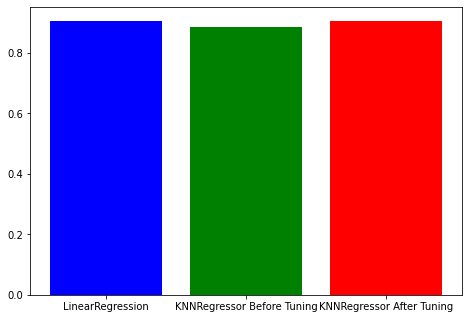

In [ ]:
fig = plt.figure()
ax = fig.add_axes([0,0,1, 1])
names = ['LinearRegression','KNNRegressor Before Tuning', 'KNNRegressor After Tuning']
accuracy = [0.9059959607091161, 0.8838502073708883, 0.9036688664124584 ]
ax.bar(names[0],accuracy[0],color='b')
ax.bar(names[1],accuracy[1],color='g')
ax.bar(names[2],accuracy[2],color='r')
plt.show()

# KNN Classifier

In [ ]:
wh = pd.read_csv('/content/drive/Shareddrives/Research_datasets/weight-height.csv') # taking dataset from google drive
wh.head()

,Gender,Height,Weight
0,Male,73.847017,241.893563
1,Male,68.781904,162.310473
2,Male,74.110105,212.740856
3,Male,71.730978,220.042470
4,Male,69.881796,206.349801


In [ ]:
wh['Gender'] = wh.Gender.replace({'Male':0,'Female':1})

In [ ]:
x = wh.drop(['Gender'], axis=1)
y = wh.Gender

In [ ]:
x.head()

,Height,Weight
0,73.847017,241.893563
1,68.781904,162.310473
2,74.110105,212.740856
3,71.730978,220.042470
4,69.881796,206.349801


In [ ]:
print(x.shape)
print(y.shape)

(8555, 2)
(8555,)


In [ ]:
#split train and test data
from sklearn.model_selection import train_test_split

In [ ]:
xtrain, xtest, ytrain, ytest = train_test_split(x, y, test_size=0.3, random_state=1)

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
knn_cls = KNeighborsClassifier()

In [ ]:
knn_cls.fit(xtrain, ytrain)

KNeighborsClassifier()

In [ ]:
knnClsAccuracy = knn_cls.score(xtest, ytest)
pred_y_knn_cls = knn_cls.predict(xtest)

In [ ]:
# Mean Square Error
from sklearn.metrics import mean_squared_error
mse_knn_cls = mean_squared_error(ytest, pred_y_knn_cls)

In [ ]:
wh_data['knn_pred_Weight'] = knn_cls.predict(x)

In [ ]:
print('Accuracy of KNeighborsClassifier ', knnClsAccuracy)
print('Mean Square Error of KNeighborsClassifier ', mse_knn_cls)
print(wh.head())
print(wh.tail())

Accuracy of KNeighborsClassifier  0.9146864043630697
Mean Square Error of KNeighborsClassifier  0.08531359563693026
   Gender     Height      Weight
0       0  73.847017  241.893563
1       0  68.781904  162.310473
2       0  74.110105  212.740856
3       0  71.730978  220.042470
4       0  69.881796  206.349801
      Gender     Height      Weight
8550       1  60.483946  110.565497
8551       1  63.423372  129.921671
8552       1  65.584057  155.942671
8553       1  67.429971  151.678405
8554       1  60.921791  131.253738


# Optimizing Algorithm with Hyper parameter Tuning

In [ ]:
# Randomized Search CV
from sklearn.model_selection import RandomizedSearchCV

In [ ]:
rscv = RandomizedSearchCV(knn_cls,grids, n_iter=300, cv=3)

In [ ]:
rscv.fit(xtrain, ytrain)

RandomizedSearchCV(cv=3, estimator=KNeighborsClassifier(), n_iter=300,
                   param_distributions={'leaf_size': [1, 2, 3, 4, 5, 6, 7, 8, 9,
                                                      10, 11, 12, 13, 14, 15,
                                                      16, 17, 18, 19, 20, 21,
                                                      22, 23, 24, 25, 26, 27,
                                                      28, 29, 30, ...],
                                        'n_neighbors': [1, 2, 3, 4, 5, 6, 7, 8,
                                                        9, 10, 11, 12, 13, 14,
                                                        15, 16, 17, 18, 19, 20,
                                                        21, 22, 23, 24, 25, 26,
                                                        27, 28, 29, 30, ...],
                                        'p': [1, 2]})

In [ ]:
results = pd.DataFrame(rscv.cv_results_)
results

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_p,param_n_neighbors,param_leaf_size,params,split0_test_score,split1_test_score,split2_test_score,mean_test_score,std_test_score,rank_test_score
0,0.004192,0.000131,0.134875,0.005458,1,237,9,"{'p': 1, 'n_neighbors': 237, 'leaf_size': 9}",0.896794,0.900802,0.920341,0.905979,0.010286,72
1,0.004117,0.000473,0.291241,0.007861,2,706,32,"{'p': 2, 'n_neighbors': 706, 'leaf_size': 32}",0.896794,0.902305,0.915331,0.904810,0.007772,181
2,0.004304,0.000011,0.060737,0.003183,1,15,4,"{'p': 1, 'n_neighbors': 15, 'leaf_size': 4}",0.905311,0.912826,0.917836,0.911991,0.005147,16
3,0.004132,0.000048,0.072761,0.013544,2,32,10,"{'p': 2, 'n_neighbors': 32, 'leaf_size': 10}",0.907315,0.911824,0.918337,0.912492,0.004524,4
4,0.003839,0.000030,0.070397,0.000315,1,54,31,"{'p': 1, 'n_neighbors': 54, 'leaf_size': 31}",0.905812,0.911323,0.918337,0.911824,0.005126,17
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
295,0.003734,0.000107,0.323059,0.004158,2,842,37,"{'p': 2, 'n_neighbors': 842, 'leaf_size': 37}",0.897295,0.901804,0.916333,0.905144,0.008123,124
296,0.003822,0.000032,0.269298,0.003563,1,672,28,"{'p': 1, 'n_neighbors': 672, 'leaf_size': 28}",0.895291,0.900301,0.916834,0.904142,0.009205,242
297,0.003889,0.000056,0.117302,0.004821,1,193,20,"{'p': 1, 'n_neighbors': 193, 'leaf_size': 20}",0.897796,0.900802,0.920341,0.906313,0.009995,68
298,0.003622,0.000038,0.214737,0.001496,2,523,45,"{'p': 2, 'n_neighbors': 523, 'leaf_size': 45}",0.895291,0.897295,0.919840,0.904142,0.011130,242


In [ ]:
knn_cls_2 = rscv.best_estimator_

In [ ]:
knn_cls_Accuracy = knn_cls_2.score(xtest, ytest)

In [ ]:
y_pred_knn_cls_2 = knn_cls_2.predict(xtest)

In [ ]:
# Mean Square Error
mse_knn_cls_2 = mean_squared_error(ytest, y_pred_knn_cls_2)

In [ ]:
print('Accuracy of KNeighborsClassifier after tuning ', knn_cls_Accuracy)
print('Mean Square Error of KNeighborsClassifier after tuning ', mse_knn_cls_2)

Accuracy of KNeighborsClassifier after tuning  0.9197506817296455
Mean Square Error of KNeighborsClassifier after tuning  0.0802493182703545


# Comparison of KNeighborsClassifer before and after Tuning

In [ ]:
print('Accuracy and Mean Square Error of KNeighborsClassifier ',knnClsAccuracy, mse_knn_cls)
print('Accuracy and Mean Square Error of KNeighborsClassifier after tuning ',knn_cls_Accuracy, mse_knn_cls_2)

Accuracy and Mean Square Error of KNeighborsClassifier  0.9146864043630697 0.08531359563693026
Accuracy and Mean Square Error of KNeighborsClassifier after tuning  0.9197506817296455 0.0802493182703545


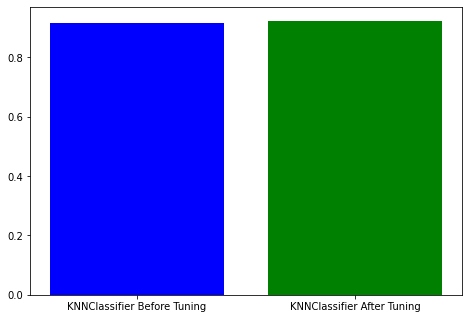

In [ ]:
fig = plt.figure()
ax = fig.add_axes([0,0,1, 1])
names = ['KNNClassifier Before Tuning', 'KNNClassifier After Tuning']
accuracy = [0.9146864043630697, 0.9244253992987924 ]
ax.bar(names[0],accuracy[0],color='b')
ax.bar(names[1],accuracy[1],color='g')
plt.show()